Import and set up data

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

df = pd.read_csv("../Data/transformed_study_data.csv")

Exploratory visualization #1

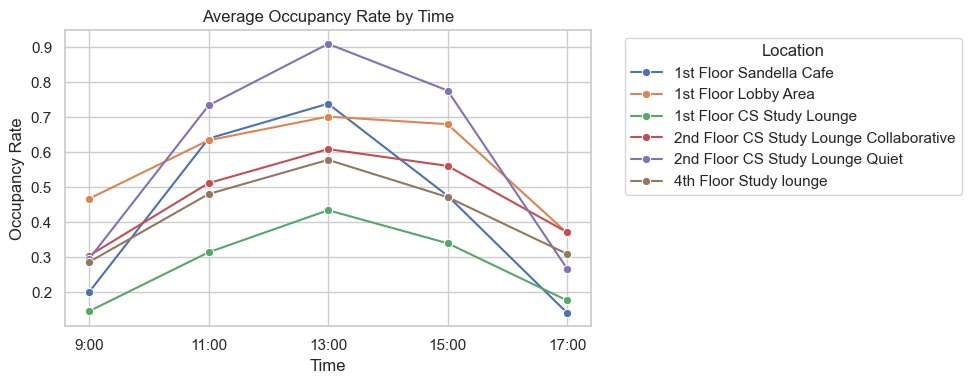

In [27]:
occupancy_time = (
    df.groupby(["time", "location"])["occupancy_rate"]
      .mean()
      .reset_index()
)

# Time ordering
time_order = ["9:00", "11:00", "13:00", "15:00", "17:00"]
occupancy_time["time"] = pd.Categorical(
    occupancy_time["time"],
    categories=time_order,
    ordered=True
)

# Location ordering
location_order = [
    "1st Floor Sandella Cafe",
    "1st Floor Lobby Area",
    "1st Floor CS Study Lounge",
    "2nd Floor CS Study Lounge Collaborative",
    "2nd Floor CS Study Lounge Quiet",
    "4th Floor Study lounge"
]
occupancy_time["location"] = pd.Categorical(
    occupancy_time["location"],
    categories=location_order,
    ordered=True
)

# Sort by time and location
occupancy_time = occupancy_time.sort_values(["time", "location"])

# Plot
plt.figure(figsize=(10, 4))
sns.lineplot(
    data=occupancy_time,
    x="time",
    y="occupancy_rate",
    hue="location",
    marker="o"
)
plt.title("Average Occupancy Rate by Time")
plt.xlabel("Time")
plt.ylabel("Occupancy Rate")

# Move legend outside plot
plt.legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()